In [4]:
import requests

url = (
    "https://mapservices.nps.gov/arcgis/rest/services/"
    "NationalDatasets/NPS_Public_Trails_Geographic/"
    "FeatureServer/0"
)

metadata = requests.get(
    url,
    params={"f": "json"},
    timeout=30
).json()

if "error" in metadata:
    raise RuntimeError(metadata["error"])

# See all available columns and their data types
for field in metadata["fields"]:
    print(field["name"], field["type"])

TRLFEATTYPE esriFieldTypeString
OBJECTID esriFieldTypeOID
TRLNAME esriFieldTypeString
TRLALTNAME esriFieldTypeString
MAPLABEL esriFieldTypeString
TRLSTATUS esriFieldTypeString
TRLSURFACE esriFieldTypeString
TRLTYPE esriFieldTypeString
TRLCLASS esriFieldTypeString
TRLUSE esriFieldTypeString
PUBLICDISPLAY esriFieldTypeString
DATAACCESS esriFieldTypeString
ACCESSNOTES esriFieldTypeString
ORIGINATOR esriFieldTypeString
UNITCODE esriFieldTypeString
UNITNAME esriFieldTypeString
UNITTYPE esriFieldTypeString
GROUPCODE esriFieldTypeString
GROUPNAME esriFieldTypeString
REGIONCODE esriFieldTypeString
CREATEDATE esriFieldTypeDate
EDITDATE esriFieldTypeDate
LINETYPE esriFieldTypeString
MAPMETHOD esriFieldTypeString
MAPSOURCE esriFieldTypeString
SOURCEDATE esriFieldTypeDate
XYACCURACY esriFieldTypeString
GEOMETRYID esriFieldTypeString
FEATUREID esriFieldTypeString
FACLOCID esriFieldTypeString
FACASSETID esriFieldTypeString
IMLOCID esriFieldTypeString
OBSERVABLE esriFieldTypeString
ISEXTANT esriField

In [5]:
import requests
import pandas as pd

url = (
    "https://mapservices.nps.gov/arcgis/rest/services/"
    "NationalDatasets/NPS_Public_Trails_Geographic/"
    "FeatureServer/0/query"
)

params = {
    "where": "1=1",
    "outFields": "*",
    "returnGeometry": "false",
    "resultRecordCount": 10,
    "f": "json"
}

response = requests.get(url, params=params, timeout=30)
response.raise_for_status()

data = response.json()

if "error" in data:
    raise RuntimeError(data["error"])

print("Returned keys:", data.keys())

df = pd.DataFrame([
    record["attributes"]
    for record in data["features"]
])


Returned keys: dict_keys(['objectIdFieldName', 'globalIdFieldName', 'geometryType', 'spatialReference', 'hasM', 'hasZ', 'fields', 'features', 'exceededTransferLimit'])


,TRLFEATTYPE,OBJECTID,TRLNAME,TRLALTNAME,MAPLABEL,TRLSTATUS,TRLSURFACE,TRLTYPE,TRLCLASS,TRLUSE,...,OBSERVABLE,ISEXTANT,OPENTOPUBLIC,ALTLANGNAME,ALTLANG,SEASONAL,SEASDESC,MAINTAINER,NOTES,Shape__Length
0,Park Trail,1,,None,,Existing,Unknown,Standard Terra Trail,Class 5: Fully Developed,Hiker/Pedestrian,...,None,True,None,None,None,Unknown,None,National Park Service,non-motorized,0.000224
1,Park Trail,2,None,None,,Existing,Unknown,Standard Terra Trail,Unknown,Pedestrian Path,...,None,Unknown,None,None,None,Unknown,None,Unknown,"{""highway"": ""footway"", ""nps:unit_code"": ""fosm""}",0.000831
2,Park Trail,3,Stony Man Horse Trail,Stony Man Horse Trail,Stony Man Horse Trail,Existing,Earth,Standard Terra Trail,Class 3: Developed,Pack and Saddle,...,None,True,None,None,None,No,None,National Park Service,,0.011114
3,Unknown,5,Commemorative Walkway,None,Commemorative Walkway,Existing,Unknown,Standard Terra Trail,Unknown,Hiker/Pedestrian,...,None,Unknown,None,None,None,Unknown,None,Unknown,"{""name"": ""Commemorative Walkway"", ""highway"": ""...",0.001119
4,Park Trail,7,None,None,None,Existing,Other,Standard Terra Trail,Class 5: Fully Developed,Hiker / Pedestrian,...,None,True,None,None,None,No,None,National Park Service,None,0.000811
5,Non-NPS Trail,8,Schuylkill River Trail acces,None,Schuylkill River Trail acces,Existing,Unknown,Standard Terra Trail,Unknown,Hiker/Pedestrian|Bicycle|Pack and Saddle,...,None,True,None,None,None,No,None,Unknown,None,0.000440
6,Park Trail,9,Ft. Moore Trail,None,Ft. Moore Trail,Existing,Native,Standard Terra Trail,Unknown,Hiker/Pedestrian|Pack and Saddle,...,None,True,None,None,None,No,None,National Park Service,Condition: Good,0.000078
7,Park Trail,10,Bridle Trail,None,Bridle Trail,Existing,Native,Standard Terra Trail,Unknown,Hiker/Pedestrian|Pack and Saddle,...,None,True,None,None,None,No,None,National Park Service,Condition: Good,0.003686
8,Park Trail,11,Bridle Trail,None,Bridle Trail,Existing,Native,Standard Terra Trail,Unknown,Hiker/Pedestrian|Pack and Saddle,...,None,True,None,None,None,No,None,National Park Service,Condition: Good,0.020342
9,Park Trail,12,National Memorial Arch,None,Joseph Plumb Martin Trail,Existing,Concrete,Standard Terra Trail,Class 5: Fully Developed,Hiker/Pedestrian|Bicycle,...,None,True,None,None,None,No,None,National Park Service,Condition: Good,0.002259


In [6]:
pd.set_option('display.max_columns', None)
df.head(10)

,TRLFEATTYPE,OBJECTID,TRLNAME,TRLALTNAME,MAPLABEL,TRLSTATUS,TRLSURFACE,TRLTYPE,TRLCLASS,TRLUSE,PUBLICDISPLAY,DATAACCESS,ACCESSNOTES,ORIGINATOR,UNITCODE,UNITNAME,UNITTYPE,GROUPCODE,GROUPNAME,REGIONCODE,CREATEDATE,EDITDATE,LINETYPE,MAPMETHOD,MAPSOURCE,SOURCEDATE,XYACCURACY,GEOMETRYID,FEATUREID,FACLOCID,FACASSETID,IMLOCID,OBSERVABLE,ISEXTANT,OPENTOPUBLIC,ALTLANGNAME,ALTLANG,SEASONAL,SEASDESC,MAINTAINER,NOTES,Shape__Length
0,Park Trail,1,,None,,Existing,Unknown,Standard Terra Trail,Class 5: Fully Developed,Hiker/Pedestrian,Public Map Display,Unrestricted,None,None,YELL,Yellowstone National Park,None,None,None,IMR,1.461283e+12,1628279465000,None,None,None,NaN,Unknown,{9CA2821D-448B-4CD8-A33A-EB30FFF30A71},1569,None,None,None,None,True,None,None,None,Unknown,None,National Park Service,non-motorized,0.000224
1,Park Trail,2,None,None,,Existing,Unknown,Standard Terra Trail,Unknown,Pedestrian Path,Public Map Display,Unrestricted,None,None,FOSM,Fort Smith National Historic Site,None,None,None,MWR,1.743437e+12,1757625484000,None,Unknown,Unknown,NaN,Unknown,{5a53bb93-59ba-4d4b-86fb-5749b9850c82},{f367c984-eadf-499f-964a-ab9ffe4cc971},None,None,None,None,Unknown,None,None,None,Unknown,None,Unknown,"{""highway"": ""footway"", ""nps:unit_code"": ""fosm""}",0.000831
2,Park Trail,3,Stony Man Horse Trail,Stony Man Horse Trail,Stony Man Horse Trail,Existing,Earth,Standard Terra Trail,Class 3: Developed,Pack and Saddle,Public Map Display,Unrestricted,None,None,SHEN,Shenandoah National Park,None,None,None,NER,NaN,1753988133000,None,Differential GPS,Unknown,1.421730e+12,<=1m,562ecf86-05f1-494e-b79c-1468d12f7862,{a727b95e-80fe-45b6-9733-bcefbb355536},48132,,None,None,True,None,None,None,No,None,National Park Service,,0.011114
3,Unknown,5,Commemorative Walkway,None,Commemorative Walkway,Existing,Unknown,Standard Terra Trail,Unknown,Hiker/Pedestrian,Public Map Display,Unrestricted,None,None,ANDE,Andersonville National Historic Site,None,None,None,SER,1.746736e+12,1755015432000,None,Unknown,Unknown,NaN,Unknown,{8b96a26f-d6a9-4968-b540-b94e657c86f0},{a66a12a2-dfec-46b2-848f-4e46613e8d2a},None,None,None,None,Unknown,None,None,None,Unknown,None,Unknown,"{""name"": ""Commemorative Walkway"", ""highway"": ""...",0.001119
4,Park Trail,7,None,None,None,Existing,Other,Standard Terra Trail,Class 5: Fully Developed,Hiker / Pedestrian,Public Map Display,Unrestricted,None,None,ROCR,Rock Creek Park,None,ROCR,Rock Creek Park,NCR,1.788358e+12,1788357788000,None,Digitized on Screen,2015 Aerial Photograph,1.420070e+12,Unknown,{3B42A6B8-AC56-49E3-ACF1-B2115B332595},None,None,None,None,None,True,None,None,None,No,None,National Park Service,None,0.000811
5,Non-NPS Trail,8,Schuylkill River Trail acces,None,Schuylkill River Trail acces,Existing,Unknown,Standard Terra Trail,Unknown,Hiker/Pedestrian|Bicycle|Pack and Saddle,Public Map Display,Unrestricted,None,None,VAFO,Valley Forge National Historical Park,None,None,None,NER,1.756206e+12,1767032208000,None,Heads-Up Digitized,Heads-up digitized from ESRI World Imagery (20...,1.420070e+12,>=1m and <5m,{2CF9FE3F-BA73-403A-8113-AE8649FA6887},None,None,None,None,None,True,None,None,None,No,None,Unknown,None,0.000440
6,Park Trail,9,Ft. Moore Trail,None,Ft. Moore Trail,Existing,Native,Standard Terra Trail,Unknown,Hiker/Pedestrian|Pack and Saddle,Public Map Display,Unrestricted,None,None,VAFO,Valley Forge National Historical Park,None,None,None,NER,1.756206e+12,1767032169000,None,Heads-Up Digitized,Heads-up digitized from DVRPC orthophotographi...,9.943776e+11,>=1m and <5m,{E38F27A2-A190-4C3F-A19C-A03D689597E1},None,None,None,None,None,True,None,None,None,No,None,National Park Service,Condition: Good,0.000078
7,Park Trail,10,Bridle Trail,None,Bridle Trail,Existing,Native,Standard Terra Trail,Unknown,Hiker/Pedestrian|Pack and Saddle,Public Map Display,Unrestricted,None,None,VAFO,Valley Forge National Historical Park,None,None,None,NER,1.756206e+12,1767032053000,None,Heads-Up Digitized,Heads-up digitized from DVRPC orthophotographi...,9

In [7]:
# count number of rows in the dataset
import requests

url = (
    "https://mapservices.nps.gov/arcgis/rest/services/"
    "NationalDatasets/NPS_Public_Trails_Geographic/"
    "FeatureServer/0/query"
)

params = {
    "where": "1=1",
    "returnCountOnly": "true",
    "f": "json"
}

response = requests.get(url, params=params, timeout=30)
response.raise_for_status()

data = response.json()

if "error" in data:
    raise RuntimeError(data["error"])

print("Total records:", data["count"])

Total records: 31377


In [9]:
print(len(records))

df_partial = pd.DataFrame(records)
df_partial.to_csv("nps_trails_partial.csv", index=False)

4000


In [29]:
params = {
    "where": "1=1",
    "returnIdsOnly": "true",
    "f": "json"
}

response = requests.get(url, params=params, timeout=60)
response.raise_for_status()

data = response.json()

if "error" in data:
    raise RuntimeError(data["error"])

ids = data["objectIds"]

print("Total IDs:", len(ids))
print("First 10 IDs:", ids[:10])

Total IDs: 31377
First 10 IDs: [1, 2, 3, 5, 7, 8, 9, 10, 11, 12]


In [34]:
import json
import time
from pathlib import Path

batch_size = 100
folder = Path("trail_batches")
folder.mkdir(exist_ok=True)

for i in range(5500, len(ids), batch_size):

    batch_ids = ids[i:i + batch_size]
    batch_file = folder / f"batch_{i:05d}.json"

    # Skip batches that were already downloaded
    if batch_file.exists():
        continue

    params = {
        "objectIds": ",".join(map(str, batch_ids)),
        "outFields": "*",
        "returnGeometry": "false",
        "f": "json"
    }

    success = False

    for attempt in range(3):
        try:
            response = requests.get(
                url, params=params, timeout=60
            )
            response.raise_for_status()
            result = response.json()

            if "error" in result:
                raise RuntimeError(result["error"])

            features = result["features"]

            returned_ids = {
                f["attributes"]["OBJECTID"]
                for f in features
            }

            if returned_ids != set(batch_ids):
                raise RuntimeError("Incomplete batch")

            # Save completed batch
            batch_file.write_text(
                json.dumps(features),
                encoding="utf-8"
            )

            success = True
            break

        except (requests.RequestException, RuntimeError) as e:
            print(f"Batch {i} failed: {e}")
            time.sleep(5 * (attempt + 1))

    if not success:
        print(f"Stopped at batch {i}. Previous batches are saved.")
        break

    print(f"Saved batch {i // batch_size + 1}")
    time.sleep(2)

Batch 19000 failed: {'code': 500, 'details': [], 'message': 'Error performing query operation'}
Saved batch 191
Batch 19100 failed: {'code': 500, 'details': [], 'message': 'Error performing query operation'}
Saved batch 192
Saved batch 193
Saved batch 194
Batch 19400 failed: {'code': 500, 'details': [], 'message': 'Error performing query operation'}
Saved batch 195
Saved batch 196
Saved batch 197
Saved batch 198
Saved batch 199
Batch 19900 failed: {'code': 500, 'details': [], 'message': 'Error performing query operation'}
Saved batch 200
Saved batch 201
Saved batch 202
Saved batch 203
Batch 20300 failed: {'code': 500, 'details': [], 'message': 'Error performing query operation'}
Saved batch 204
Batch 20400 failed: {'code': 500, 'details': [], 'message': 'Error performing query operation'}
Saved batch 205
Saved batch 206
Batch 20600 failed: {'code': 500, 'details': [], 'message': 'Error performing query operation'}
Saved batch 207
Saved batch 208
Saved batch 209
Saved batch 210
Batch 21

In [35]:
from pathlib import Path

folder = Path("trail_batches")
files = list(folder.glob("batch_*.json"))

print("Completed batches:", len(files))
print("Approximately downloaded:", len(files) * 100)

Completed batches: 314
Approximately downloaded: 31400


In [ ]:
import pandas as pd
import json
from pathlib import Path

folder = Path("trail_batches")

all_records = []

for file in sorted(folder.glob("batch_*.json")):
    features = json.loads(file.read_text(encoding="utf-8"))

    for feature in features:
        all_records.append(feature["attributes"])

df = pd.DataFrame(all_records)

print("Shape:", df.shape)
display(df.head(10))

Shape: (31377, 42)


,TRLFEATTYPE,OBJECTID,TRLNAME,TRLALTNAME,MAPLABEL,TRLSTATUS,TRLSURFACE,TRLTYPE,TRLCLASS,TRLUSE,PUBLICDISPLAY,DATAACCESS,ACCESSNOTES,ORIGINATOR,UNITCODE,UNITNAME,UNITTYPE,GROUPCODE,GROUPNAME,REGIONCODE,CREATEDATE,EDITDATE,LINETYPE,MAPMETHOD,MAPSOURCE,SOURCEDATE,XYACCURACY,GEOMETRYID,FEATUREID,FACLOCID,FACASSETID,IMLOCID,OBSERVABLE,ISEXTANT,OPENTOPUBLIC,ALTLANGNAME,ALTLANG,SEASONAL,SEASDESC,MAINTAINER,NOTES,Shape__Length
0,Park Trail,1,,None,,Existing,Unknown,Standard Terra Trail,Class 5: Fully Developed,Hiker/Pedestrian,Public Map Display,Unrestricted,None,None,YELL,Yellowstone National Park,None,None,None,IMR,1.461283e+12,1628279465000,None,None,None,NaN,Unknown,{9CA2821D-448B-4CD8-A33A-EB30FFF30A71},1569,None,None,None,None,True,None,None,None,Unknown,None,National Park Service,non-motorized,0.000224
1,Park Trail,2,None,None,,Existing,Unknown,Standard Terra Trail,Unknown,Pedestrian Path,Public Map Display,Unrestricted,None,None,FOSM,Fort Smith National Historic Site,None,None,None,MWR,1.743437e+12,1757625484000,None,Unknown,Unknown,NaN,Unknown,{5a53bb93-59ba-4d4b-86fb-5749b9850c82},{f367c984-eadf-499f-964a-ab9ffe4cc971},None,None,None,None,Unknown,None,None,None,Unknown,None,Unknown,"{""highway"": ""footway"", ""nps:unit_code"": ""fosm""}",0.000831
2,Park Trail,3,Stony Man Horse Trail,Stony Man Horse Trail,Stony Man Horse Trail,Existing,Earth,Standard Terra Trail,Class 3: Developed,Pack and Saddle,Public Map Display,Unrestricted,None,None,SHEN,Shenandoah National Park,None,None,None,NER,NaN,1753988133000,None,Differential GPS,Unknown,1.421730e+12,<=1m,562ecf86-05f1-494e-b79c-1468d12f7862,{a727b95e-80fe-45b6-9733-bcefbb355536},48132,,None,None,True,None,None,None,No,None,National Park Service,,0.011114
3,Unknown,5,Commemorative Walkway,None,Commemorative Walkway,Existing,Unknown,Standard Terra Trail,Unknown,Hiker/Pedestrian,Public Map Display,Unrestricted,None,None,ANDE,Andersonville National Historic Site,None,None,None,SER,1.746736e+12,1755015432000,None,Unknown,Unknown,NaN,Unknown,{8b96a26f-d6a9-4968-b540-b94e657c86f0},{a66a12a2-dfec-46b2-848f-4e46613e8d2a},None,None,None,None,Unknown,None,None,None,Unknown,None,Unknown,"{""name"": ""Commemorative Walkway"", ""highway"": ""...",0.001119
4,Park Trail,7,None,None,None,Existing,Other,Standard Terra Trail,Class 5: Fully Developed,Hiker / Pedestrian,Public Map Display,Unrestricted,None,None,ROCR,Rock Creek Park,None,ROCR,Rock Creek Park,NCR,1.788358e+12,1788357788000,None,Digitized on Screen,2015 Aerial Photograph,1.420070e+12,Unknown,{3B42A6B8-AC56-49E3-ACF1-B2115B332595},None,None,None,None,None,True,None,None,None,No,None,National Park Service,None,0.000811
5,Non-NPS Trail,8,Schuylkill River Trail acces,None,Schuylkill River Trail acces,Existing,Unknown,Standard Terra Trail,Unknown,Hiker/Pedestrian|Bicycle|Pack and Saddle,Public Map Display,Unrestricted,None,None,VAFO,Valley Forge National Historical Park,None,None,None,NER,1.756206e+12,1767032208000,None,Heads-Up Digitized,Heads-up digitized from ESRI World Imagery (20...,1.420070e+12,>=1m and <5m,{2CF9FE3F-BA73-403A-8113-AE8649FA6887},None,None,None,None,None,True,None,None,None,No,None,Unknown,None,0.000440
6,Park Trail,9,Ft. Moore Trail,None,Ft. Moore Trail,Existing,Native,Standard Terra Trail,Unknown,Hiker/Pedestrian|Pack and Saddle,Public Map Display,Unrestricted,None,None,VAFO,Valley Forge National Historical Park,None,None,None,NER,1.756206e+12,1767032169000,None,Heads-Up Digitized,Heads-up digitized from DVRPC orthophotographi...,9.943776e+11,>=1m and <5m,{E38F27A2-A190-4C3F-A19C-A03D689597E1},None,None,None,None,None,True,None,None,None,No,None,National Park Service,Condition: Good,0.000078
7,Park Trail,10,Bridle Trail,None,Bridle Trail,Existing,Native,Standard Terra Trail,Unknown,Hiker/Pedestrian|Pack and Saddle,Public Map Display,Unrestricted,None,None,VAFO,Valley Forge National Historical Park,None,None,None,NER,1.756206e+12,1767032053000,None,Heads-Up Digitized,Heads-up digitized from DVRPC orthophotographi...,9

In [37]:
print("Rows and columns:", df.shape)
print("Unique OBJECTIDs:", df["OBJECTID"].nunique())
print("Duplicates:", df["OBJECTID"].duplicated().sum())

df.info()

display(df.describe(include="all").T)

Rows and columns: (31377, 42)
Unique OBJECTIDs: 31377
Duplicates: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31377 entries, 0 to 31376
Data columns (total 42 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   TRLFEATTYPE    31377 non-null  object 
 1   OBJECTID       31377 non-null  int64  
 2   TRLNAME        26821 non-null  object 
 3   TRLALTNAME     12814 non-null  object 
 4   MAPLABEL       26963 non-null  object 
 5   TRLSTATUS      31377 non-null  object 
 6   TRLSURFACE     31377 non-null  object 
 7   TRLTYPE        31377 non-null  object 
 8   TRLCLASS       31377 non-null  object 
 9   TRLUSE         31377 non-null  object 
 10  PUBLICDISPLAY  31377 non-null  object 
 11  DATAACCESS     31377 non-null  object 
 12  ACCESSNOTES    0 non-null      object 
 13  ORIGINATOR     0 non-null      object 
 14  UNITCODE       31367 non-null  object 
 15  UNITNAME       30367 non-null  object 
 16  UNITTYPE       0 non-null 

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
TRLFEATTYPE,31377,17,Park Trail,27187,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OBJECTID,31377.0,NaN,NaN,NaN,16304.004494,9433.057305,1.0,8133.0,16242.0,24449.0,32714.0
TRLNAME,26821,8555,,2846,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TRLALTNAME,12814,2200,,3682,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MAPLABEL,26963,8001,,4219,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TRLSTATUS,31377,11,Existing,30638,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TRLSURFACE,31377,38,Unknown,11385,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TRLTYPE,31377,12,Standard Terra Trail,28920,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TRLCLASS,31377,16,Unknown,14897,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TRLUSE,31377,112,Hiker/Pedestrian,9910,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [40]:
df.to_csv("nps_trails_partial.csv", index=False)

In [1]:
import pandas as pd
import numpy as np
df = pd.read_csv("nps_trails_partial.csv")

In [2]:
df_clean = df.copy()

df_clean = df_clean.replace(
    ["Unknown", "", "None"],
    pd.NA
)

missing_pct = (
    df_clean.isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

display(missing_pct)

OPENTOPUBLIC     100.000000
UNITTYPE         100.000000
OBSERVABLE       100.000000
IMLOCID          100.000000
ALTLANG          100.000000
LINETYPE         100.000000
ALTLANGNAME      100.000000
ACCESSNOTES      100.000000
ORIGINATOR       100.000000
SEASDESC          86.576155
FACASSETID        80.798037
XYACCURACY        77.703413
GROUPNAME         75.144214
SOURCEDATE        73.464640
GROUPCODE         71.660771
TRLALTNAME        60.971412
FACLOCID          57.185199
MAPSOURCE         53.398987
MAPMETHOD         50.027090
TRLCLASS          47.477452
MAINTAINER        45.029799
NOTES             37.677280
TRLSURFACE        36.284540
SEASONAL          34.483858
ISEXTANT          30.436307
TRLUSE            29.591739
CREATEDATE        20.024222
FEATUREID         18.233101
MAPLABEL          15.036492
TRLNAME           14.641298
TRLFEATTYPE        7.390764
TRLTYPE            4.315263
UNITNAME           3.218918
TRLSTATUS          0.799949
UNITCODE           0.031870
Shape__Length      0

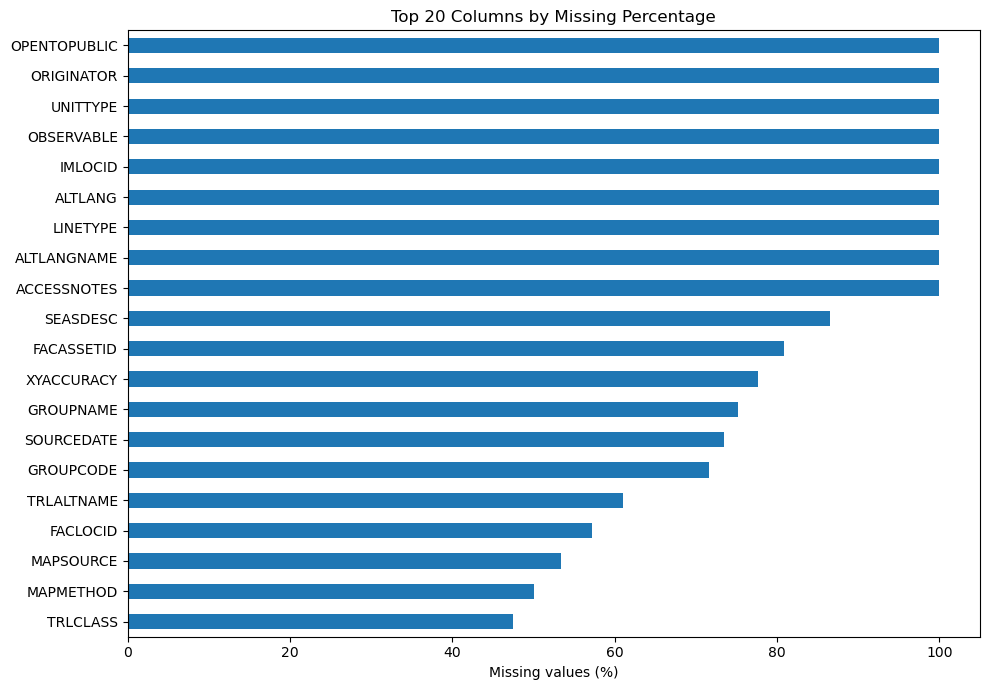

In [51]:
import matplotlib.pyplot as plt

missing_pct.head(20).sort_values().plot(
    kind="barh",
    figsize=(10, 7)
)

plt.xlabel("Missing values (%)")
plt.title("Top 20 Columns by Missing Percentage")
plt.tight_layout()
plt.show()

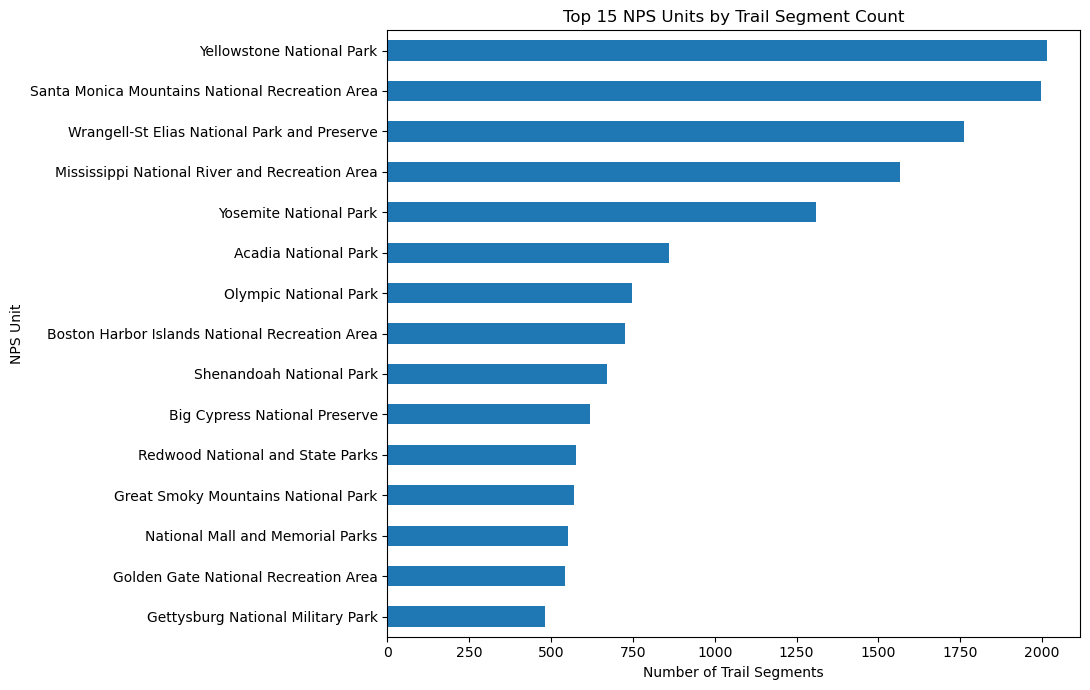

In [43]:
# park vs count
park_counts = (
    df_clean["UNITNAME"]
    .value_counts()
    .head(15)
    .sort_values()
)

park_counts.plot(
    kind="barh",
    figsize=(11, 7)
)

plt.xlabel("Number of Trail Segments")
plt.ylabel("NPS Unit")
plt.title("Top 15 NPS Units by Trail Segment Count")
plt.tight_layout()
plt.show()

In [45]:
top_parks = (
    df_clean["UNITNAME"]
    .value_counts()
    .head(10)
    .index
)

subset = df_clean[
    df_clean["UNITNAME"].isin(top_parks)]

In [46]:
trail_use_counts = pd.crosstab(
    subset["UNITNAME"],
    subset["TRLUSE"]
)

display(trail_use_counts)

TRLUSE,Bicycle,Bike | Hike | PackOrSaddle,Connector,Four-Wheel Drive Vehicle > 50” in Tread Width,Hike,Hike | PackOrSaddle,Hiker/Pedestrian,Hiker/Pedestrian,"Hiker/Pedestrian, Bicycle","Hiker/Pedestrian, Cross-Country Ski",Hiker/Pedestrian|All-Terrain Vehicle,Hiker/Pedestrian|All-Terrain Vehicle|Four-Wheel Drive Vehicle > 50” in Tread Width,Hiker/Pedestrian|Bicycle,Hiker/Pedestrian|Pack and Saddle,Hiker/Pedestrian|Pack and Saddle|Bicycle,Motorized Watercraft,Pack and Saddle,Snowshoe|Cross-Country Ski
UNITNAME,,,,,,,,,,,,,,,,,,
Big Cypress National Preserve,0,0,0,0,0,0,616,0,0,0,0,0,0,0,0,3,0,0
Olympic National Park,0,0,0,0,740,6,0,0,0,0,0,0,0,0,0,0,0,0
Santa Monica Mountains National Recreation Area,0,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Shenandoah National Park,0,0,1,1,0,0,626,0,0,0,0,0,0,0,0,0,42,0
Wrangell-St Elias National Park and Preserve,0,0,0,0,0,0,967,0,0,0,794,1,0,0,0,0,0,0
Yellowstone National Park,0,0,0,0,0,0,1941,0,47,24,0,0,0,0,0,0,0,0
Yosemite National Park,11,0,0,0,0,0,671,5,0,0,0,0,149,435,27,0,0,4


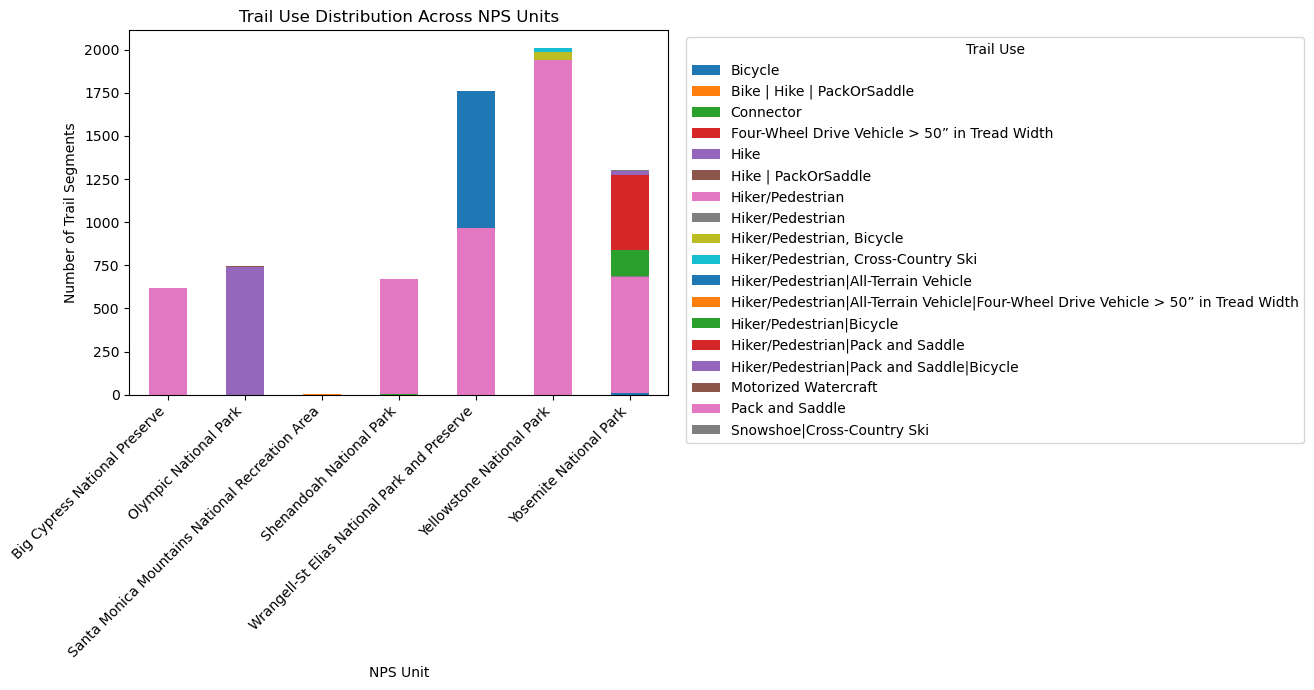

In [47]:
trail_use_counts.plot(
    kind="bar",
    stacked=True,
    figsize=(13, 7)
)

plt.xlabel("NPS Unit")
plt.ylabel("Number of Trail Segments")
plt.title("Trail Use Distribution Across NPS Units")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Trail Use", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

TRLSTATUS,Existing
UNITNAME,
Acadia National Park,860
Big Cypress National Preserve,619
Boston Harbor Islands National Recreation Area,725
Mississippi National River and Recreation Area,1566
Olympic National Park,746
Santa Monica Mountains National Recreation Area,1997
Shenandoah National Park,670
Wrangell-St Elias National Park and Preserve,1762
Yellowstone National Park,2015


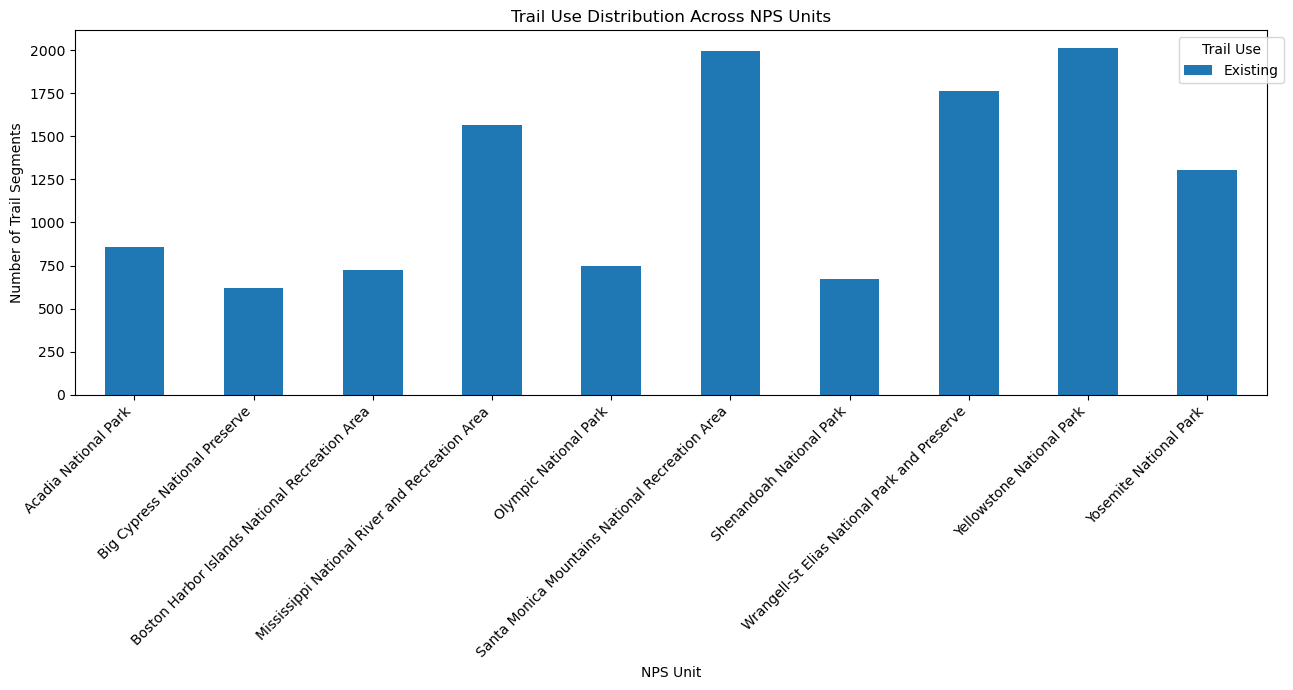

30638


31377

In [57]:
top_parks = (
    df_clean["UNITNAME"]
    .value_counts()
    .head(10)
    .index)

subset = df_clean[
    df_clean["UNITNAME"].isin(top_parks)]
trail_use_counts = pd.crosstab(
    subset["UNITNAME"],
    subset["TRLSTATUS"]
)

display(trail_use_counts)
trail_use_counts.plot(
    kind="bar",
    stacked=True,
    figsize=(13, 7)
)

plt.xlabel("NPS Unit")
plt.ylabel("Number of Trail Segments")
plt.title("Trail Use Distribution Across NPS Units")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Trail Use", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

count = (df_clean['TRLSTATUS'] == 'Existing').sum()
print(count)
df_clean.shape[0]

In [3]:
df_clean = df_clean[df_clean["TRLSTATUS"] == "Existing"].copy() # remove non-existing trails

In [4]:
df_clean.shape

(30638, 42)

handle yellowstone data first

Number of trail segments: 2015


TRLUSE
Hiker/Pedestrian                       1941
Hiker/Pedestrian, Bicycle                47
Hiker/Pedestrian, Cross-Country Ski      24
<NA>                                      3
Name: count, dtype: int64

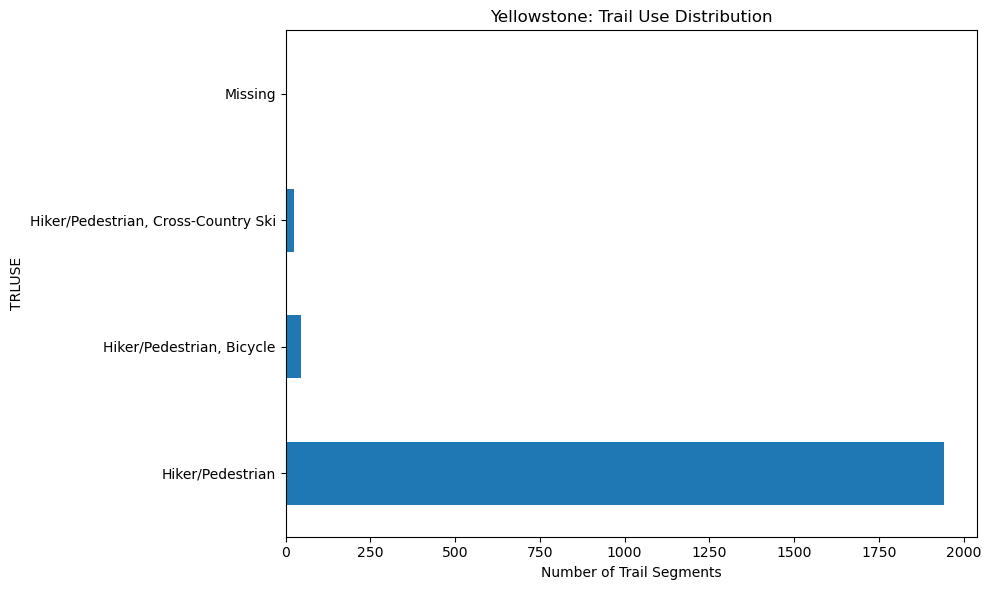

In [5]:
park = df_clean[
    df_clean["UNITCODE"] == "YELL"
].copy()

print("Number of trail segments:", len(park))

display(
    park["TRLUSE"].value_counts(dropna=False)
)
import matplotlib.pyplot as plt

park["TRLUSE"].fillna("Missing").value_counts().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Yellowstone: Trail Use Distribution")
plt.xlabel("Number of Trail Segments")
plt.tight_layout()
plt.show()

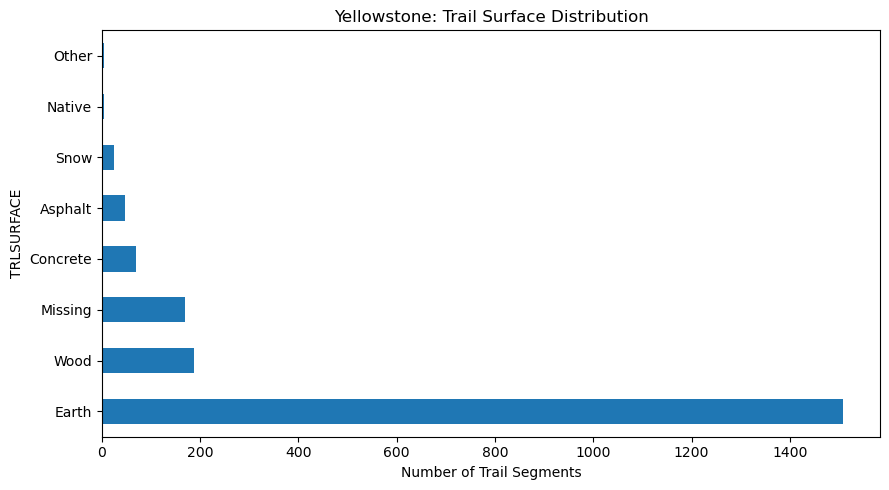

In [6]:
park["TRLSURFACE"].fillna("Missing").value_counts().plot(
    kind="barh",
    figsize=(9, 5)
)

plt.title("Yellowstone: Trail Surface Distribution")
plt.xlabel("Number of Trail Segments")
plt.tight_layout()
plt.show()